<!-- DOC-BANNER -->
# Feature Scaling — Normalization / MinMaxScaler (Day 25)

> **Playlist:** CampusX Day 25 *Feature Scaling - Normalization | MinMaxScaling | MaxAbsScaling | RobustScaling*.
> **Purpose:** Min-max normalization on synthetic `Age/Salary/Purchased` dicts + `wine_data.csv` cols `[0,1,2]` (`Class` label, `Alcohol`, `Malic Acid`): hand formula `(x-min)/(max-min)` → per-column demo → `MinMaxScaler` fit/transform/fit_transform → correct split→fit-train→transform-test → `Pipeline` + toy `LogisticRegression` → `feature_range=(-1,1)` → unseen-value demo. Viz: `kdeplot(Alcohol)`, `scatter(Alcohol vs Malic Acid, hue=Class)`, before/after scatter x2 + KDEs, `describe()`.
> **After studying:** you can apply `x' = (x-min)/(max-min)`, choose MinMax vs Standard vs Normalizer (table inside), and avoid fit-on-test leakage.


# Feature Scaling: Normalization in Machine Learning

> **Learning path:** What → Why → How → Mental Model → Code → Internal behavior → ML connection → Mistakes → Experiment → Interview → Cheat Sheet

This notebook teaches **normalization as a feature-scaling technique**. In many introductory ML discussions, *normalization* means scaling numerical features to a fixed range, commonly **0 to 1**, using Min-Max scaling.

> **Terminology note:** Some libraries and fields use *normalization* to mean other operations, such as making each row/vector have unit length. Here, we will first study **Min-Max scaling**, then distinguish it from standardization and vector normalization.


## 1. What is normalization?

Imagine a dataset with two features:

- `Age`: values around 18–60
- `Salary`: values around 20,000–200,000

The features use very different numerical ranges. **Min-Max normalization** transforms each feature so its minimum becomes 0 and its maximum becomes 1.

For a value `x`, the formula is:

\[
x_{scaled} = \frac{x - x_{min}}{x_{max} - x_{min}}
\]

Where:
- `x` is the original value.
- `x_min` is the minimum value in that feature.
- `x_max` is the maximum value in that feature.
- `x_scaled` is the transformed value.

The minimum maps to 0, the maximum maps to 1, and values between them map between 0 and 1.


## 2. Why do we normalize features?

Algorithms can be affected by feature scale. For example, a distance-based algorithm may treat a difference of 10,000 in salary as much larger than a difference of 10 in age, even if both features are meaningful.

Scaling can be useful for:
- **K-Nearest Neighbors (KNN)**, which uses distances.
- **K-Means**, which uses distances to cluster centers.
- **Support Vector Machines (SVM)**, where feature scale can affect the optimization.
- **Gradient-based models and neural networks**, where scaling often helps optimization.

Scaling is not automatically beneficial for every algorithm. Tree-based models such as decision trees and random forests usually do not require feature scaling for their split decisions.

### Mental model

Think of each feature as a ruler. One ruler measures age in tens; another measures salary in hundreds of thousands. Min-Max scaling puts each ruler onto a common 0-to-1 range. It changes the **scale**, not the order of values.


## 3. Calculate normalization by hand

Suppose a feature contains `[10, 20, 30, 40, 50]`.

For the value `30`:
- Minimum = 10
- Maximum = 50

\[
x_{scaled} = \frac{30 - 10}{50 - 10} = \frac{20}{40} = 0.5
\]

The complete feature should map to `[0, 0.25, 0.5, 0.75, 1]`.


In [2]:
values = [10, 20, 30, 40, 50]

minimum = min(values)
maximum = max(values)

normalized = [(x - minimum) / (maximum - minimum) for x in values]

print("Minimum:", minimum)
print("Maximum:", maximum)
print("Normalized values:", normalized)

Minimum: 10
Maximum: 50
Normalized values: [0.0, 0.25, 0.5, 0.75, 1.0]


### What the code is doing

1. It finds the smallest and largest values in the feature.
2. For every value, it subtracts the minimum.
3. It divides the result by the feature's range (`maximum - minimum`).
4. It stores the transformed values in a new list.

**Important:** If every value is identical, then `maximum - minimum` is zero and this manual formula would divide by zero. A scaler library handles constant features safely; do not implement the formula blindly without considering this edge case.


## 4. Normalize a Pandas DataFrame manually

Usually, a dataset has multiple numerical columns. Min-Max scaling is performed **separately for each feature/column**, not by using one minimum and maximum for the entire DataFrame.


In [3]:
import pandas as pd

df = pd.DataFrame({
    "Age": [20, 25, 30, 35, 40],
    "Salary": [20000, 40000, 60000, 80000, 100000]
})

df

,Age,Salary
0,20,20000
1,25,40000
2,30,60000
3,35,80000
4,40,100000


In [4]:
df_min = df.min()
df_max = df.max()

normalized_df = (df - df_min) / (df_max - df_min)

print("Original data:")
display(df)

print("Normalized data:")
display(normalized_df)

Original data:


,Age,Salary
0,20,20000
1,25,40000
2,30,60000
3,35,80000
4,40,100000


Normalized data:


,Age,Salary
0,0.00,0.00
1,0.25,0.25
2,0.50,0.50
3,0.75,0.75
4,1.00,1.00


### Read the result correctly

- The smallest age becomes `0.0` and the largest age becomes `1.0`.
- The smallest salary becomes `0.0` and the largest salary becomes `1.0`.
- The columns are scaled independently, so their relative numerical ranges no longer dominate simply because one column uses larger units.

The values are still related to their original positions within each feature's range. Normalization does **not** mean that every row sums to 1.


## 5. The recommended tool: `MinMaxScaler` from scikit-learn

For ML workflows, use scikit-learn's `MinMaxScaler`. Its default output range is `(0, 1)`.


### 1. Formula then API — hand min-max → `MinMaxScaler`
Hand: `(df-min)/(max-min)` → [0,1]. API: `fit_transform(train)`, `transform(test)`; `feature_range=(-1,1)` rescales the interval. Unseen values outside train min/max map outside [0,1] — expected, not a bug.

In [5]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_array = scaler.fit_transform(df)

scaled_df = pd.DataFrame(
    scaled_array,
    columns=df.columns,
    index=df.index
)

scaled_df

,Age,Salary
0,0.00,0.00
1,0.25,0.25
2,0.50,0.50
3,0.75,0.75
4,1.00,1.00


### Understand `fit`, `transform`, and `fit_transform`

- **`fit(X)`**: learns the minimum and maximum for each feature from `X`.
- **`transform(X)`**: applies the learned scaling parameters to data.
- **`fit_transform(X)`**: learns the parameters and transforms that same data in one step.

The scaler stores learned information such as `data_min_`, `data_max_`, and `scale_`. You can inspect these attributes.


In [6]:
print("Minimum learned per feature:", scaler.data_min_)
print("Maximum learned per feature:", scaler.data_max_)
print("Scale factor per feature:", scaler.scale_)

Minimum learned per feature: [   20. 20000.]
Maximum learned per feature: [4.e+01 1.e+05]
Scale factor per feature: [5.00e-02 1.25e-05]


## 6. The most important ML rule: split before scaling

### Correct workflow

1. Separate features (`X`) and target (`y`).
2. Split into training and test sets.
3. Fit the scaler **only on `X_train`**.
4. Transform `X_train` and `X_test` using that same fitted scaler.
5. Train the model on scaled training data and evaluate on scaled test data.

Why? If you fit the scaler on the entire dataset before splitting, the minimum and maximum from the test set influence the preprocessing parameters. That is a form of **data leakage**: information from the held-out test set has entered the training workflow.

The test set should simulate unseen data.


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

data = pd.DataFrame({
    "Age": [19, 22, 25, 28, 31, 34, 37, 40, 45, 50],
    "Salary": [18000, 25000, 30000, 42000, 50000, 62000, 70000, 85000, 110000, 150000],
    "Purchased": [0, 0, 0, 0, 1, 0, 1, 1, 1, 1]
})

X = data.drop("Purchased", axis=1)
y = data["Purchased"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(
    X_train_scaled, columns=X.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    X_test_scaled, columns=X.columns, index=X_test.index
)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)
display(X_train_scaled)
display(X_test_scaled)

Training shape: (7, 2)
Testing shape: (3, 2)


,Age,Salary
6,0.652174,0.529412
5,0.521739,0.435294
1,0.000000,0.000000
8,1.000000,1.000000
7,0.782609,0.705882
4,0.391304,0.294118
2,0.130435,0.058824


,Age,Salary
0,-0.130435,-0.082353
3,0.260870,0.200000
9,1.217391,1.470588


### Why is `transform()` used on the test set?

The test set must use the **training set's** minimum and maximum. Do not call `fit_transform(X_test)`: that would calculate a different scale from the test data and make the train/test values inconsistent.

Also, values in the test set are **not guaranteed to fall between 0 and 1**. If a test value is below the training minimum or above the training maximum, Min-Max scaling can produce a value outside that range. This is expected.


In [8]:
print("Training minima:", scaler.data_min_)
print("Training maxima:", scaler.data_max_)
print("Scaled training minimums:", X_train_scaled.min().to_dict())
print("Scaled training maximums:", X_train_scaled.max().to_dict())
print("Scaled test values:")
display(X_test_scaled)

Training minima: [2.2e+01 2.5e+04]
Training maxima: [4.5e+01 1.1e+05]
Scaled training minimums: {'Age': 0.0, 'Salary': 0.0}
Scaled training maximums: {'Age': 1.0, 'Salary': 1.0}
Scaled test values:


,Age,Salary
0,-0.130435,-0.082353
3,0.260870,0.200000
9,1.217391,1.470588


## 7. What happens internally?

For each feature, `MinMaxScaler` learns the feature's range from the training data and calculates a linear transformation.

With the default feature range `(0, 1)`, the transformation is equivalent to:

\[
X_{scaled} = \frac{X - X_{min}}{X_{max} - X_{min}}
\]

The learned parameters are then reused whenever `transform()` is called. The scaler does not need to rediscover the minimum and maximum each time.

### Shape stays the same

If `X_train` has shape `(700, 4)`, the scaled output also has shape `(700, 4)`. Scaling changes the values, not the number of rows or columns.


In [9]:
print("Before scaling:", X_train.shape)
print("After scaling:", X_train_scaled.shape)

Before scaling: (7, 2)
After scaling: (7, 2)


## 8. Normalization vs standardization vs vector normalization

These terms are sometimes used loosely, so identify the actual operation being discussed.

| Method | Main idea | Typical formula | Typical result |
|---|---|---|---|
| Min-Max scaling | Map each feature to a chosen range | `(x - min) / (max - min)` for range 0–1 | Values usually in 0–1 for the data used to fit |
| Standardization | Center using the mean and scale by standard deviation | `(x - mean) / standard deviation` | Mean near 0 and standard deviation near 1 on fitted data |
| Vector normalization | Scale each sample/vector to unit norm | `x / ||x||` | Each nonzero vector has norm 1 |

Min-Max scaling is sensitive to extreme values because the minimum and maximum determine the mapping. Standardization is also affected by outliers, especially through the mean and standard deviation, but it does not force values into a fixed interval.

Scikit-learn's `Normalizer` is a different tool from `MinMaxScaler`: it usually normalizes each **sample/row**, rather than learning a separate minimum and maximum for each feature.


In [10]:
from sklearn.preprocessing import StandardScaler, Normalizer

sample = pd.DataFrame({
    "Feature_A": [10, 20, 30, 40],
    "Feature_B": [100, 200, 300, 400]
})

minmax_result = MinMaxScaler().fit_transform(sample)
standard_result = StandardScaler().fit_transform(sample)
vector_result = Normalizer().fit_transform(sample)

print("Min-Max scaling:")
display(pd.DataFrame(minmax_result, columns=sample.columns))

print("Standardization:")
display(pd.DataFrame(standard_result, columns=sample.columns))

print("Row-wise vector normalization:")
display(pd.DataFrame(vector_result, columns=sample.columns))

Min-Max scaling:


,Feature_A,Feature_B
0,0.000000,0.000000
1,0.333333,0.333333
2,0.666667,0.666667
3,1.000000,1.000000


Standardization:


,Feature_A,Feature_B
0,-1.341641,-1.341641
1,-0.447214,-0.447214
2,0.447214,0.447214
3,1.341641,1.341641


Row-wise vector normalization:


,Feature_A,Feature_B
0,0.099504,0.995037
1,0.099504,0.995037
2,0.099504,0.995037
3,0.099504,0.995037


## 9. Common mistakes to avoid

1. **Scaling before train/test split:** can leak information from the test set.
2. **Calling `fit_transform()` separately on train and test:** learns different scaling parameters.
3. **Scaling the target accidentally:** generally scale feature columns (`X`) only unless target scaling is deliberately required for a specific regression workflow.
4. **Assuming every algorithm needs scaling:** decision trees and random forests typically do not need it.
5. **Assuming test values must be between 0 and 1:** the range guarantee applies to the fitted data, not necessarily unseen values.
6. **Using one global minimum and maximum for all columns:** ordinary feature scaling works column by column.
7. **Forgetting preprocessing at prediction time:** new data must be transformed with the already-fitted scaler.
8. **Ignoring constant features:** a constant feature has zero range; use a tested library implementation rather than a naive formula.


## 10. Use a Pipeline to reduce mistakes

A scikit-learn `Pipeline` keeps scaling and model training together. When the pipeline is fitted on training data, the scaler learns only from the training fold/data. This is particularly useful when doing cross-validation and hyperparameter tuning.


### 2. Leak-free habit — `train_test_split` + `Pipeline`
Split first, fit scaler on train only. The `LogisticRegression` here is a toy correctness check, not a tuned model. Trailing cells list MaxAbs/Robust variants (detailed in topic_notes.md). Internal dups preserved: split+scale block x2, before/after scatter x2, double imports.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = Pipeline([
    ("scaler", MinMaxScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train , y_train)
predictions = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))

Accuracy: 0.6666666666666666


## 11. Experiments to build intuition

Run each experiment and explain what you observe.

### Experiment A: Change the units
Multiply `Salary` by 100. Its Min-Max scaled values should remain the same, apart from tiny floating-point differences, because both the values and range are multiplied by the same positive constant.

### Experiment B: Add an extreme value
Add a very large value to a feature. The previous values will be compressed closer to 0 because the maximum has increased.

### Experiment C: Try a custom range
`MinMaxScaler(feature_range=(-1, 1))` maps the fitted minimum to -1 and maximum to 1.

### Experiment D: Try an unseen value
Fit a scaler on training values `[10, 20, 30]`, then transform `40`. It should map above 1 because 40 is beyond the training maximum.


In [12]:
scaler_01 = MinMaxScaler()
original = pd.DataFrame({"Salary": [20000, 40000, 60000, 80000]})
changed_units = pd.DataFrame({"Salary": [2000000, 4000000, 6000000, 8000000]})

print("Original units:")
display(pd.DataFrame(scaler_01.fit_transform(original), columns=["Salary"]))

print("Changed units:")
display(pd.DataFrame(MinMaxScaler().fit_transform(changed_units), columns=["Salary"]))

custom_scaler = MinMaxScaler(feature_range=(-1, 1))
display(pd.DataFrame(
    custom_scaler.fit_transform(original),
    columns=["Salary"]
))

scaler = MinMaxScaler()
scaler.fit(pd.DataFrame({"value": [10, 20, 30]}))
print("Transforming unseen value 40:", scaler.transform([[40]])[0, 0])

Original units:


,Salary
0,0.000000
1,0.333333
2,0.666667
3,1.000000


Changed units:


,Salary
0,0.000000
1,0.333333
2,0.666667
3,1.000000


,Salary
0,-1.000000
1,-0.333333
2,0.333333
3,1.000000


Transforming unseen value 40: 1.5


e:\MACHINE_LEARNING\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


## 12. Interview questions

### Q1. What is Min-Max normalization?
A feature-scaling method that maps feature values to a specified range, usually 0 to 1, using the feature's minimum and maximum.

### Q2. What is the formula?
For range 0 to 1: `(x - x_min) / (x_max - x_min)`.

### Q3. Why split before scaling?
To prevent information from the test set influencing the preprocessing parameters.

### Q4. Why use `fit_transform()` on training data but `transform()` on test data?
Training data is used to learn scaling parameters. Test data must reuse those same parameters.

### Q5. Does Min-Max scaling remove outliers?
No. It rescales values; it does not remove outliers. An extreme minimum or maximum can compress the other values.

### Q6. Must the transformed test set be between 0 and 1?
No. Unseen values outside the training range can transform outside 0–1.

### Q7. Which models often benefit from scaling?
Distance-based methods such as KNN and K-Means, SVMs, and many gradient-based models/neural networks.

### Q8. Do decision trees usually need normalization?
Usually not, because their split decisions depend on feature ordering and thresholds rather than distances between differently scaled features.


## 13. Practice questions

Try these before looking at the answer key.

1. Normalize `[5, 10, 15]` to the range 0–1 by hand.
2. What will the minimum and maximum of the fitted feature become after Min-Max scaling to `(0, 1)`?
3. Why is `scaler.fit_transform(X_test)` the wrong default in a train/test workflow?
4. If a test value is greater than the training maximum, can its scaled value be greater than 1?
5. Which should normally be scaled: `X`, `y`, or both?
6. Is Min-Max scaling the same as `Normalizer` from scikit-learn?
7. Name two algorithms that often benefit from feature scaling and one family that usually does not need it.


### Answer key

1. Minimum = 5, maximum = 15. The results are `[0, 0.5, 1]`.
2. The fitted minimum maps to 0 and fitted maximum maps to 1.
3. It learns a new minimum and maximum from test data instead of reusing training parameters.
4. Yes. The transformed value can exceed 1.
5. Normally scale feature columns `X`; scaling `y` is a separate, intentional decision.
6. No. `MinMaxScaler` scales each feature using learned min/max; `Normalizer` scales each sample/vector to a norm such as 1.
7. KNN and K-Means often benefit; tree-based models usually do not require scaling.


## 14. Cheat sheet

- **Purpose:** put numerical features on comparable scales.
- **Min-Max formula:** `(x - min) / (max - min)` for range 0–1.
- **Library:** `from sklearn.preprocessing import MinMaxScaler`
- **Correct workflow:** split → `fit_transform(X_train)` → `transform(X_test)`.
- **Never fit preprocessing on the test set** in a standard train/test workflow.
- **Shape:** remains unchanged.
- **Outliers:** can strongly affect the result.
- **Test values:** may fall outside 0–1.
- **Not the same as:** standardization (`StandardScaler`) or row-wise vector normalization (`Normalizer`).
- **Often useful for:** KNN, K-Means, SVM, neural networks/gradient-based methods.
- **Usually not needed for:** decision trees and random forests.

### One-line memory rule

**Fit on training data; transform both training and test data with the same fitted scaler.**


## TYPES OF NORMALIZATION
 
  min max   scaling         

  mean normalization
  
  max  absolute
  
  robust scaling

WHAT is MIN MAX SCALING  
#       X- X(MIN) / X(MAX) - X(MIN)



# U ARE SQUEEZING THE WHIOLE DATA ON THE O TO 1 SCALE 

In [13]:

import matplotlib.pyplot as plt 
import  seaborn as sns 
import pandas as pd 
import numpy as  np 



In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="husl",
    font="sans-serif",
    font_scale=1.1,
    rc={
        "figure.figsize": (10, 6),
        "figure.dpi": 120,
        "axes.titlesize": 18,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.25,
        "lines.linewidth": 2.5,
        "lines.markersize": 7,
        "legend.frameon": False,
        "figure.autolayout": True
    }
)

plt.rcParams["figure.facecolor"] = "#1e1e2f"
plt.rcParams["axes.facecolor"] = "#282840"
plt.rcParams["axes.labelcolor"] = "#eeeeff"
plt.rcParams["text.color"] = "#eeeeff"
plt.rcParams["xtick.color"] = "#ccccdd"
plt.rcParams["ytick.color"] = "#ccccdd"
plt.rcParams["grid.color"] = "#777799"

In [15]:
df = pd.read_csv(r"E:\MACHINE_LEARNING\DATA_SETS\wine_data.csv" , header= None , usecols= [0,1,2])


df.columns=[ 'Class label' ,'Alcohol' , 'Malic Acid']
df 

,Class label,Alcohol,Malic Acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59
...,...,...,...
173,3,13.71,5.65
174,3,13.40,3.91
175,3,13.27,4.28
176,3,13.17,2.59


<Axes: xlabel='Alcohol', ylabel='Density'>

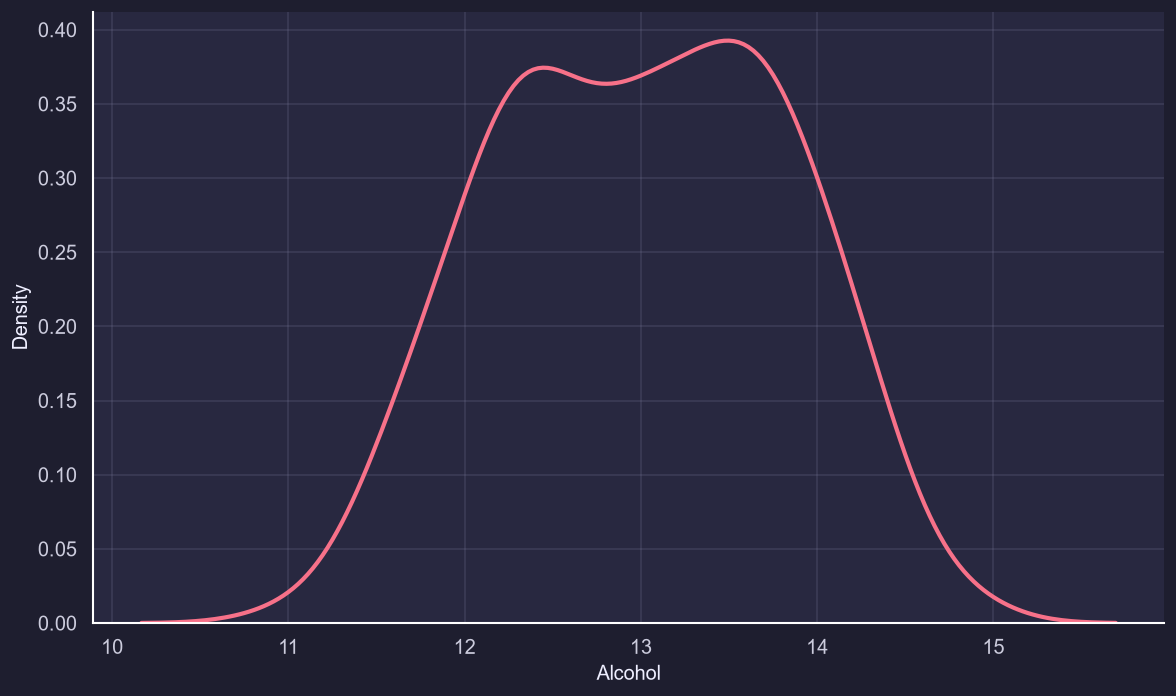

In [16]:
sns.kdeplot(df["Alcohol"])

<Axes: xlabel='Alcohol', ylabel='Malic Acid'>

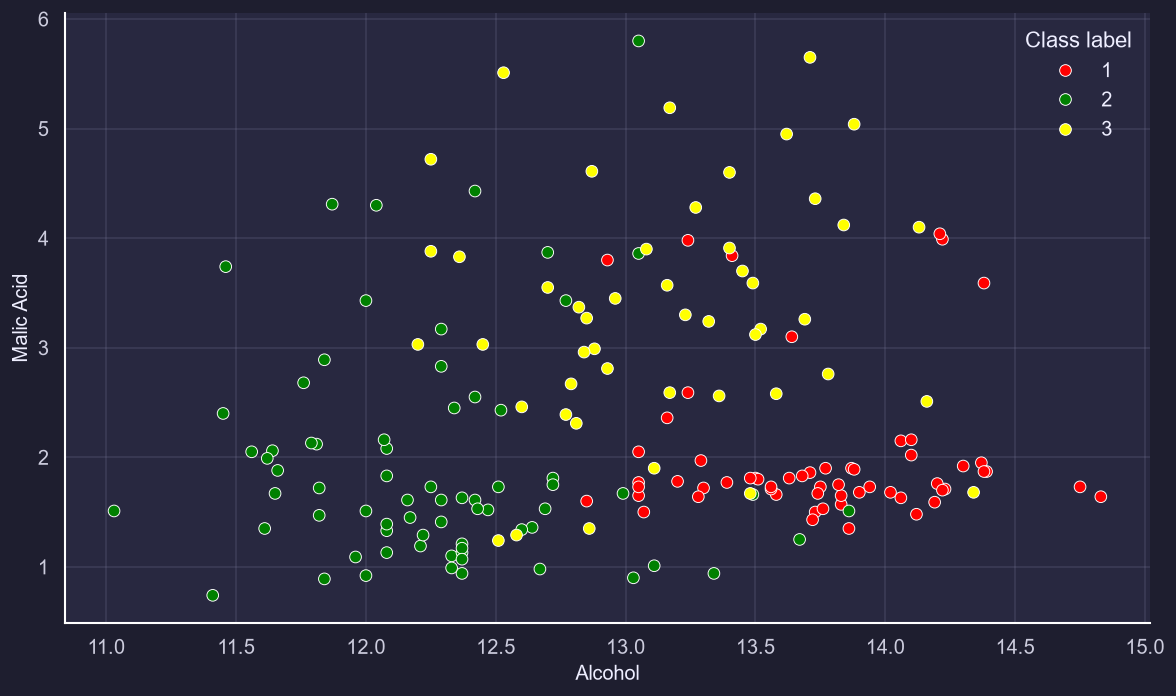

In [17]:
color_d = {1 : 'red' , 2 : "green" , 3 : "yellow"}
sns.scatterplot(data=df, x='Alcohol', y='Malic Acid', hue='Class label' , palette=  color_d)

In [18]:
df

,Class label,Alcohol,Malic Acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59
...,...,...,...
173,3,13.71,5.65
174,3,13.40,3.91
175,3,13.27,4.28
176,3,13.17,2.59


# Train Test Split 

In [19]:
from sklearn.model_selection import train_test_split as tts  
x_train ,x_test , y_train , y_test = tts(df.drop('Class label' ,axis= 1 ) , df["Class label"] , test_size= 0.2  , random_state = 23)



x_train.shape

(142, 2)

In [20]:
from sklearn.preprocessing import MinMaxScaler 
scaler = MinMaxScaler ()  



scaler.fit(x_train)


x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)



df

,Class label,Alcohol,Malic Acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59
...,...,...,...
173,3,13.71,5.65
174,3,13.40,3.91
175,3,13.27,4.28
176,3,13.17,2.59


In [21]:
x_train_scaled = pd.DataFrame(x_train_scaled , columns= x_train.columns)
x_test_scaled = pd.DataFrame(x_test_scaled , columns= x_test.columns  )

In [22]:
x_train_scaled

,Alcohol,Malic Acid
0,0.344737,0.337945
1,0.165789,0.225296
2,0.878947,0.239130
3,0.310526,0.088933
4,0.331579,0.480237
...,...,...
137,0.839474,0.642292
138,0.255263,0.152174
139,0.671053,0.181818
140,0.665789,0.191700


In [23]:
np.round(x_train_scaled.describe() ,2)

,Alcohol,Malic Acid
count,142.00,142.00
mean,0.52,0.32
std,0.22,0.22
min,0.00,0.00
25%,0.35,0.17
50%,0.53,0.22
75%,0.69,0.47
max,1.00,1.00


In [24]:
from sklearn.model_selection import train_test_split as tts
from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import numpy as np

x_train, x_test, y_train, y_test = tts(
    df.drop('Class label', axis=1),
    df['Class label'],
    test_size=0.2,
    random_state=23
)

scaler = MinMaxScaler()

scaler.fit(x_train)

x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

x_train_scaled = pd.DataFrame(x_train_scaled, columns=x_train.columns)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=x_test.columns)

np.round(x_train_scaled.describe(), 1)

,Alcohol,Malic Acid
count,142.0,142.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.4,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


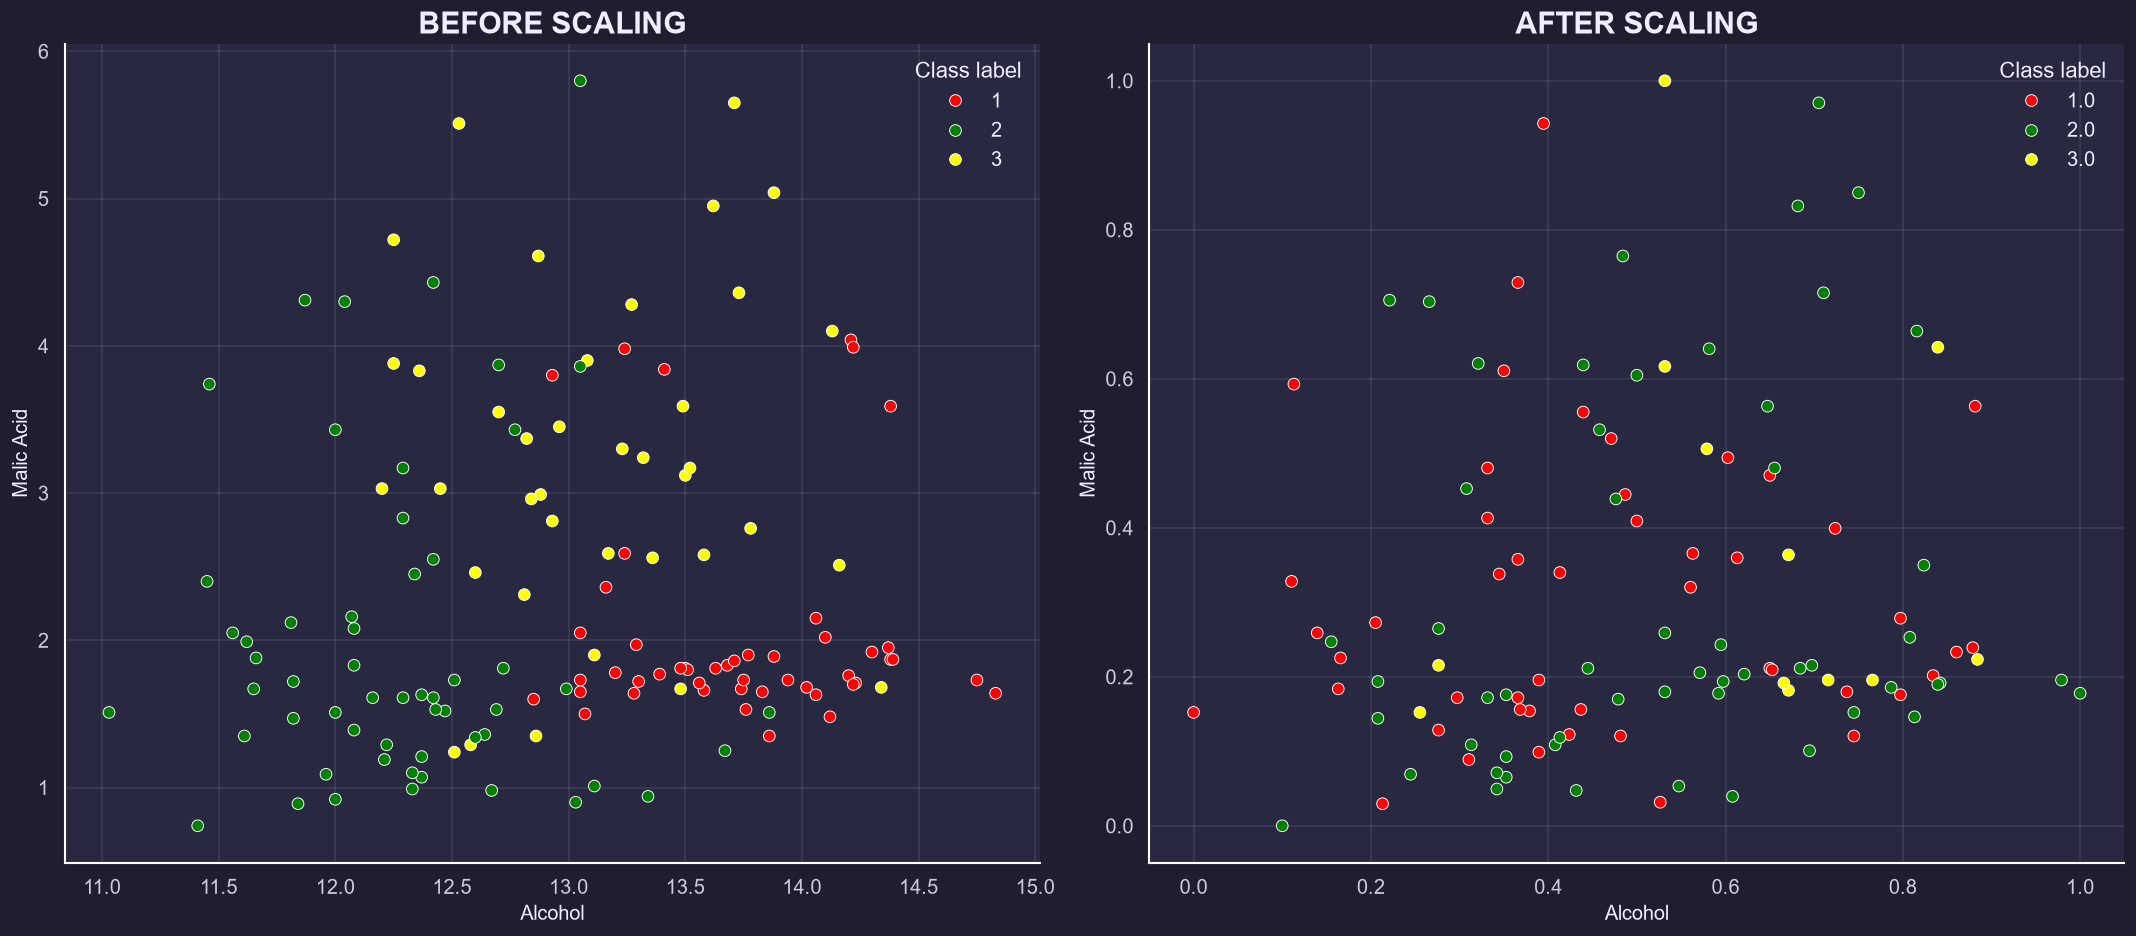

In [25]:

color_d = {1: 'red', 2: 'green', 3: 'yellow'}

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(18, 8))

sns.scatterplot(
    data=x_train,
    x='Alcohol',
    y='Malic Acid',
    hue=y_train,
    palette=color_d,
    ax=ax1
)

ax1.set_title("BEFORE SCALING")

sns.scatterplot(
    data=x_train_scaled,
    x='Alcohol',
    y='Malic Acid',
    hue=y_train,
    palette=color_d,
    ax=ax2
)

ax2.set_title("AFTER SCALING")

plt.show()


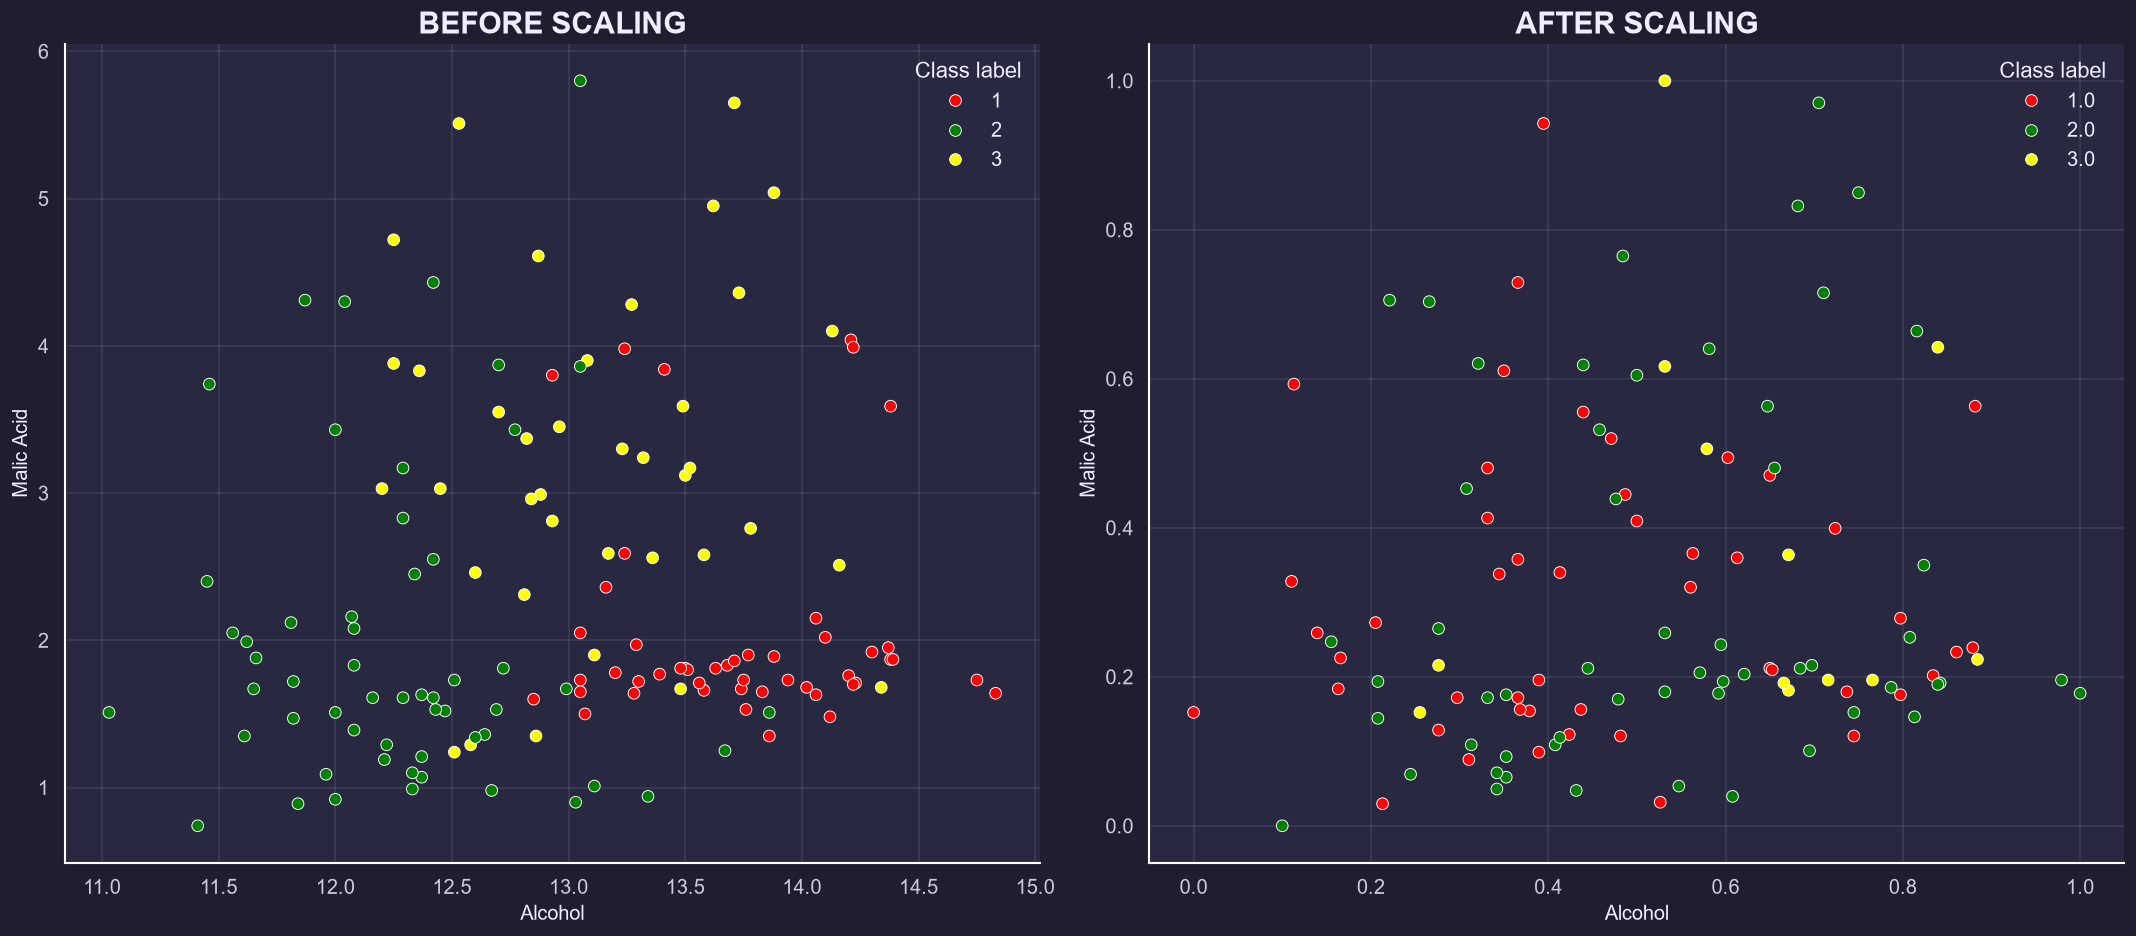

In [26]:
color_d = {1: 'red', 2: 'green', 3: 'yellow'}

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(18, 8))

sns.scatterplot(
    data=x_train,
    x='Alcohol',
    y='Malic Acid',
    hue=y_train,
    palette=color_d,
    ax=ax1
)

ax1.set_title("BEFORE SCALING")

sns.scatterplot(
    data=x_train_scaled,
    x='Alcohol',
    y='Malic Acid',
    hue=y_train,
    palette=color_d,
    ax=ax2
)

ax2.set_title("AFTER SCALING")

plt.show()

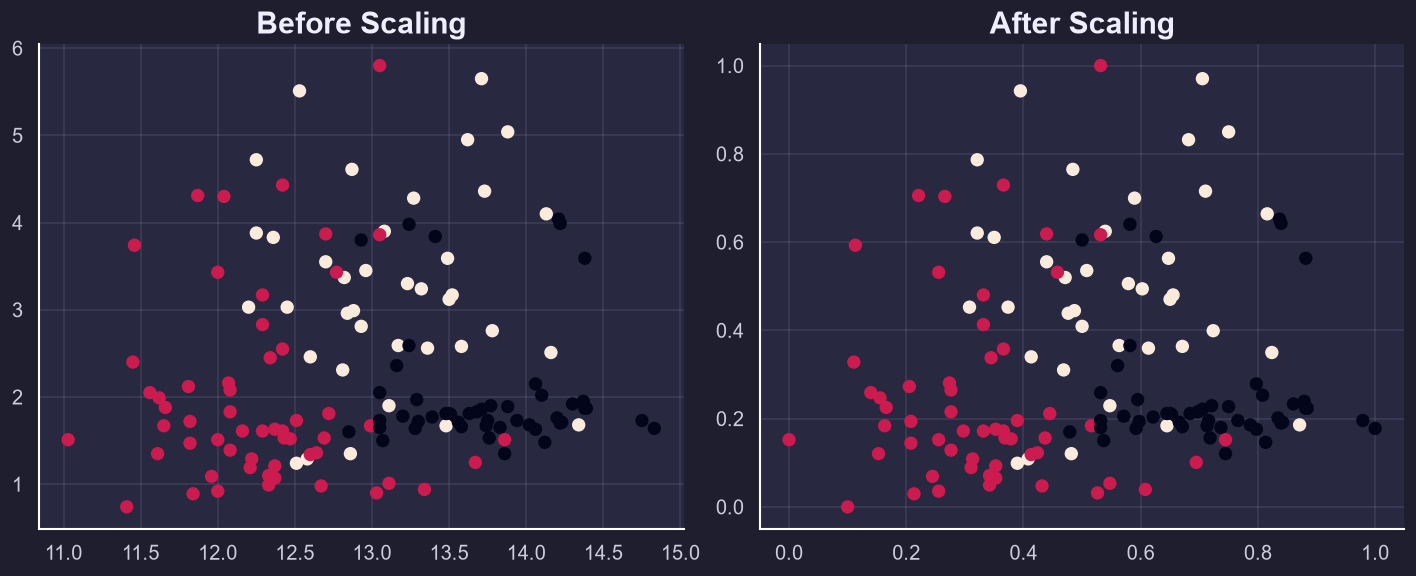

In [27]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(x_train['Alcohol'], x_train['Malic Acid'], c=y_train)
ax1.set_title("Before Scaling")

ax2.scatter(x_train_scaled['Alcohol'], x_train_scaled['Malic Acid'], c=y_train)
ax2.set_title("After Scaling")

plt.show()

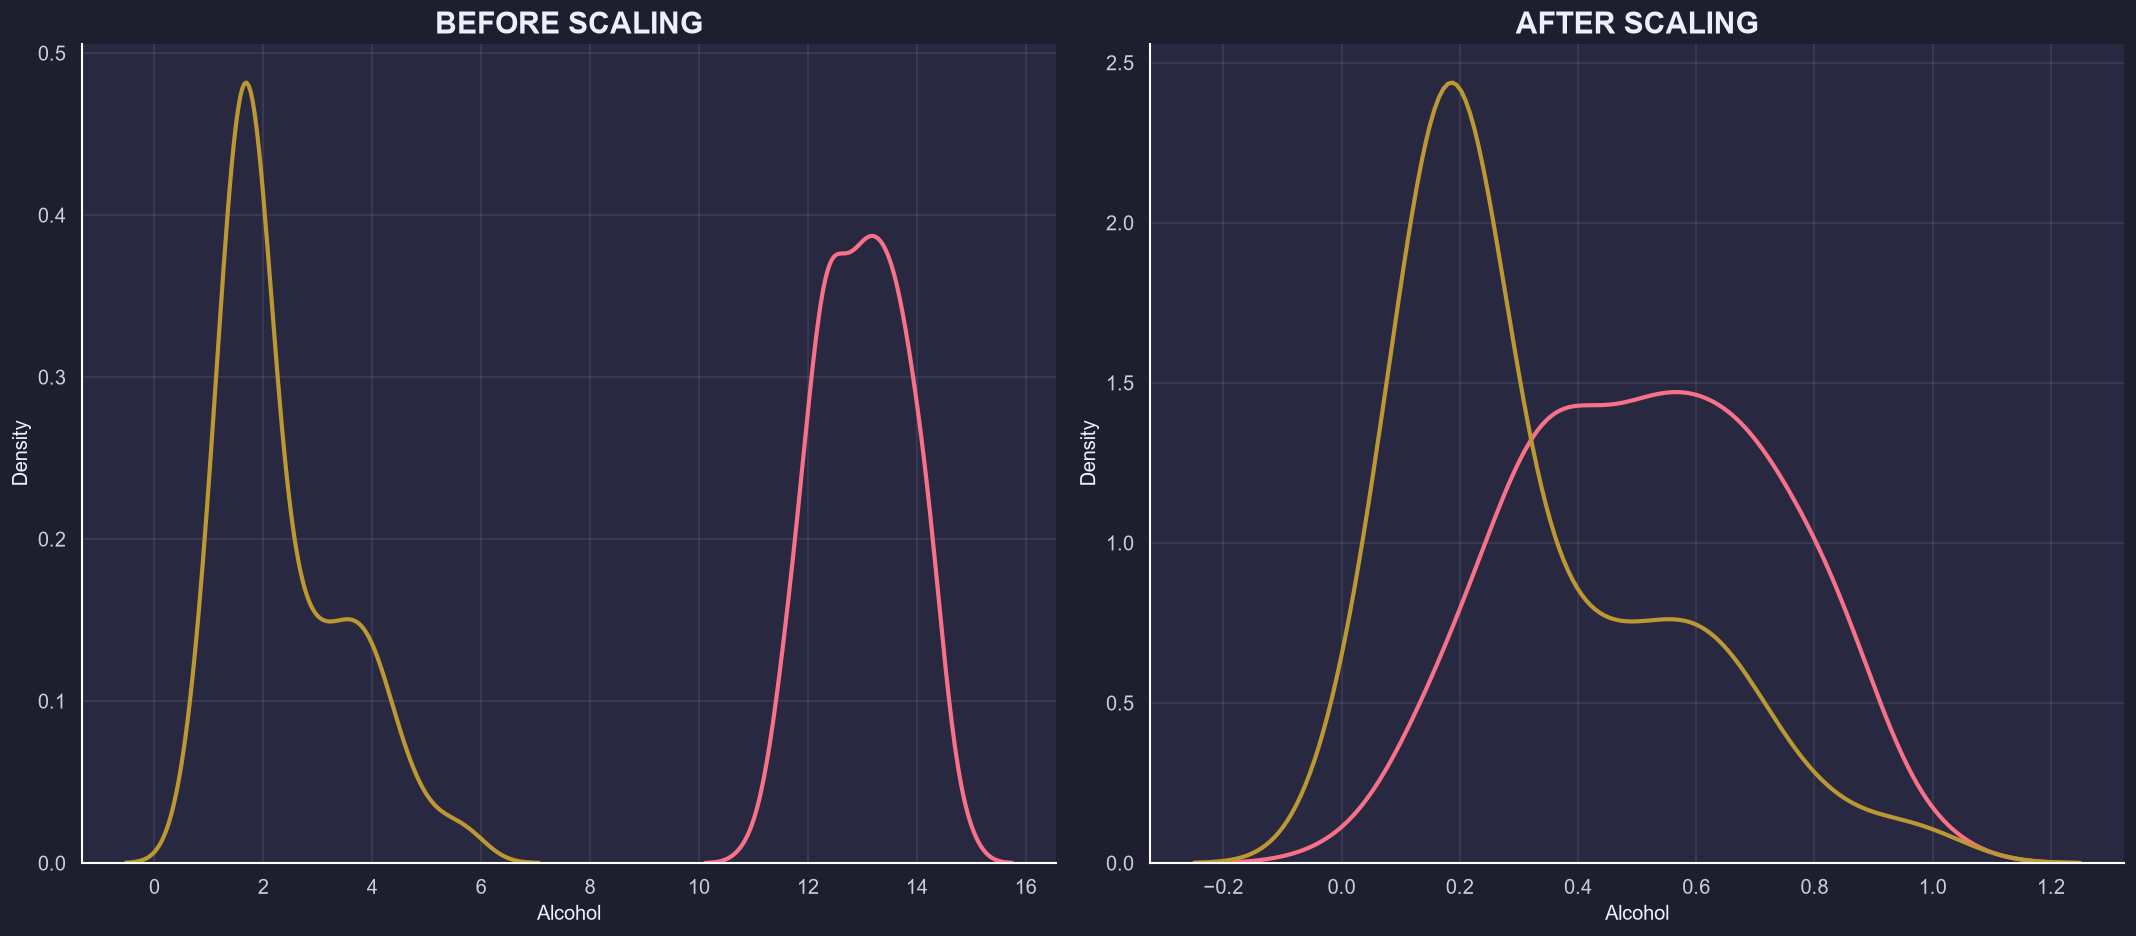

In [28]:
# color_d = {1: 'red', 2: 'green', 3: 'yellow'}

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(18, 8))

sns.kdeplot(
   
   x_train['Alcohol'] ,
    ax=ax1
)

sns.kdeplot(
   
   x_train['Malic Acid'] ,
    ax=ax1
)
ax1.set_title("BEFORE SCALING")

sns.kdeplot(
   
   x_train_scaled['Alcohol'] ,
    ax=ax2
)

sns.kdeplot(
   
   x_train_scaled['Malic Acid'] ,
    ax=ax2
)
ax2.set_title("AFTER SCALING")

plt.show()

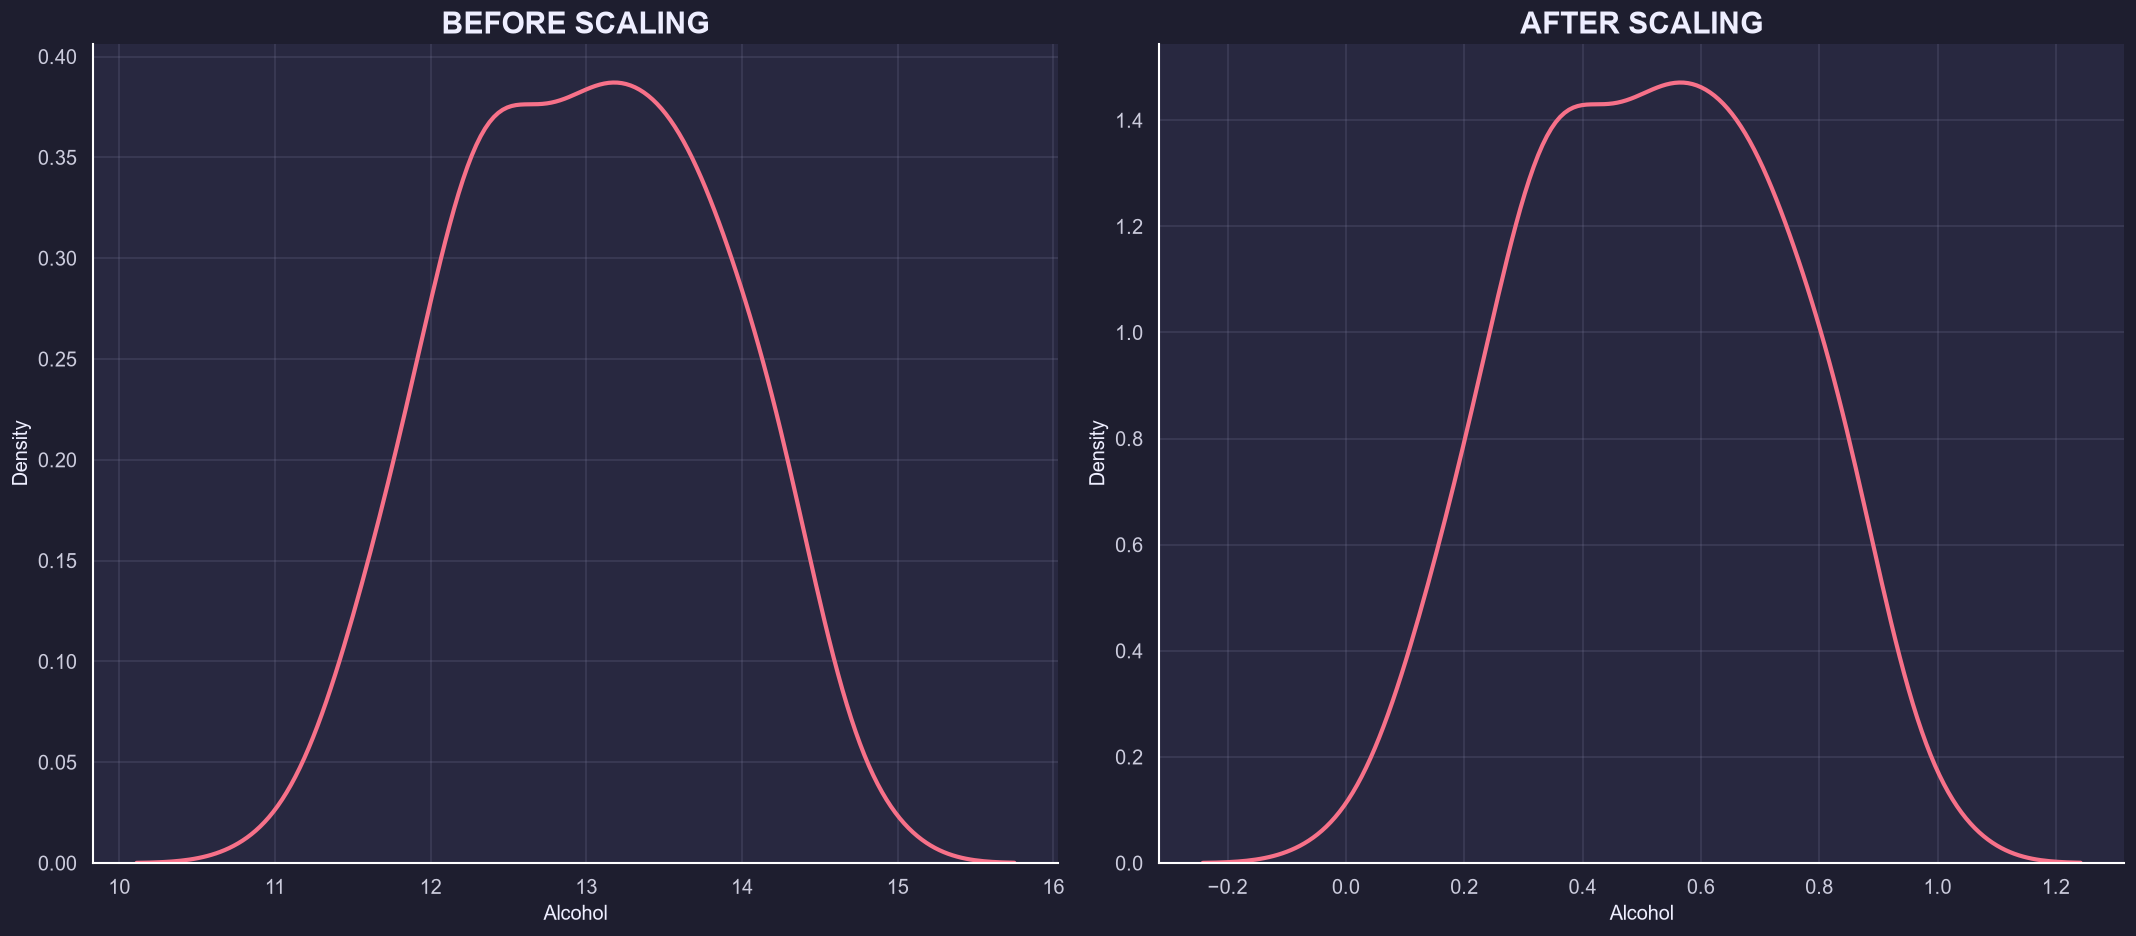

In [ ]:
# color_d = {1: 'red', 2: 'green', 3: 'yellow'}

fig ,(ax1, ax2) = plt.subplots(ncols=2, figsize=(18, 8))

sns.kdeplot(
   
   x_train['Alcohol'] ,
    ax=ax1
)


ax1.set_title("BEFORE SCALING")

sns.kdeplot(
   
   x_train_scaled['Alcohol'] ,
    ax=ax2
)

ax2.set_title("AFTER SCALING")

plt.show()

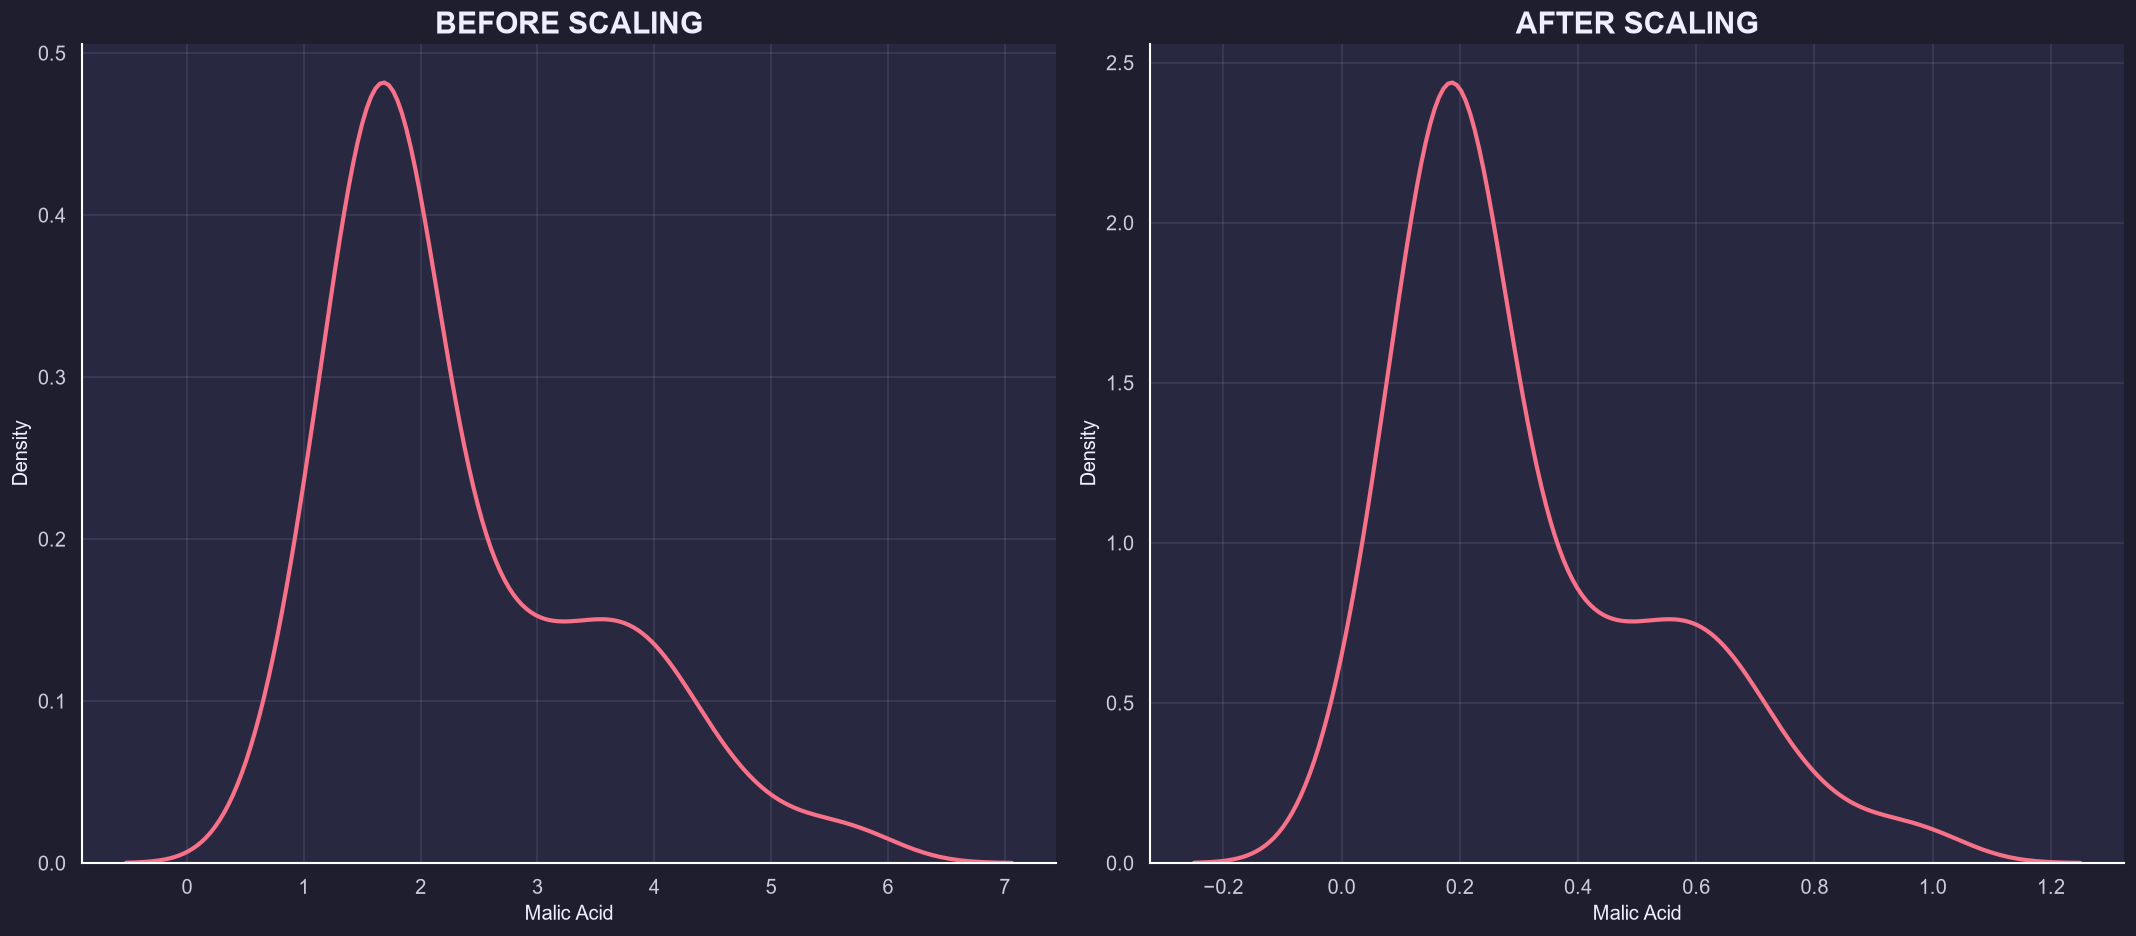

In [30]:
# color_d = {1: 'red', 2: 'green', 3: 'yellow'}

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(18, 8))

sns.kdeplot(
   
   x_train['Malic Acid'] ,
    ax=ax1
)


ax1.set_title("BEFORE SCALING")

sns.kdeplot(
   
   x_train_scaled['Malic Acid'] ,
    ax=ax2
)

ax2.set_title("AFTER SCALING")

plt.show()

# MEAN NORMALIZATION


## Xi' =  Xi - X(MEAN) /  X(MAX) - X(MEAN)


## if value is less then mean   then negative 

##  used rarely no class in sklearn  use standorization insteead

#  MaxAbsScaling 

## USEFUL FOR THE SPARSE daTA 

## Xi' = Xi / abs(X(MAX))

## class in the max sklearn

# ROBUST SCALING 

## Xi'= Xi -X(MEDIAN)  / IQR {75 per - 25 per}



## usefullness robust to outliers  

# NORMALIZATION VS STANDARISATION 


##  ask for is feature scaling req 


## for most of the prob standarization is used 



##  normalization 
## min max used when you know the min  max known 


## when outlier use robust scaling 
## when sparse then use MaxAbScaling


<!-- EXPERIMENT -->
### Experiment: stretch the range, break the bounds
Change `feature_range` to `(0, 1)` and predict every output value's new interval. Then transform a value *above* the train maximum and confirm it maps outside the range — expected behavior, not a bug, and the reason train/test ranges must come from train alone.

<!-- DOC-BANNER -->
## Key takeaways (Day 25)
- MinMax = bounded [0,1] (or custom range); sensitive to outliers (min/max move). Standard = unbounded z-scores. Row-wise `Normalizer` (unit norm) is a third, different thing — see comparison table in-notebook + topic_notes.md.
- Interview line: *MinMax when bounded features/lat-long/image pixels and no wild outliers; Standard when Gaussian-ish/algorithm assumes zero-mean; Robust when outliers dominate.*
